# 08. Out-of-time check on the 2024 sample

**Question:** does what the model learned from 2025 videos still work on videos from a different year?

**Why it matters:** the test set (2026) comes from the same platform period as train. The 2024 sample was never
used for training, tuning or testing, so it is a fair, independent check. A strong drop would mean that
what makes a video viral drifts over time.

**Method:** the final model (same features and settings as in `05`) is trained on 2025 train data, with early
stopping on validation. It then scores the 2024 videos. The label is built the same way: top 10% of views within
each posting month. Everything learned from data (country list, sound counts) comes from train only.

**Metric:** PR-AUC divided by the random baseline (the "ratio"), because the baseline can differ between datasets.
Ratio 1 means no better than chance, 2 means twice as good as chance (what we had on validation and test).

## 1. Load the 2025 to 2026 features and define the feature lists

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd().parent
P = ROOT / "data" / "processed"

tr = pl.read_parquet(P / "train_features.parquet").to_pandas()
va = pl.read_parquet(P / "validation_features.parquet").to_pandas()
te = pl.read_parquet(P / "test_features.parquet").to_pandas()
for d in (tr, va, te):
    d["sound_log"] = np.log1p(d["sound_freq"])

CAT = ["country", "language", "type"]
NUM = ["hour", "weekday", "duration_ms", "caption_len", "n_hashtags",
       "n_mentions", "n_onscreen", "is_ad", "is_shop_video", "sound_log"]
FEATS = CAT + NUM
FEATS_NS = [c for c in FEATS if c != "sound_log"]   # variant without the sound feature (see section 3)
print(tr.shape, va.shape, te.shape)

(27597, 23) (14398, 23) (17999, 23)


## 2. Build the 2024 dataset with the same pipeline

- **Label:** `is_viral` = views in the top 10% of the video's posting month (same rule as `03`).
- **Features:** same definitions as in `04`.
- **Learned from train only:** the list of the 10 biggest countries and the sound counts.
  For 2024 videos, `sound_freq` counts how many train videos use the same sound.

In [2]:
train_raw = pl.read_parquet(P / "train_labeled.parquet").select(["sound_id", "country"])
sound_counts = train_raw.group_by("sound_id").len().rename({"len": "sound_freq"})
top_countries = (train_raw.group_by("country").len()
                 .sort("len", descending=True).head(10)["country"].to_list())

raw24 = pl.read_parquet(ROOT / "data" / "sample_recent" / "recent_60k.parquet").sort("posted_at")
raw24 = raw24.with_columns(pl.col("posted_at").dt.truncate("1mo").alias("cohort"))
raw24 = raw24.with_columns(
    (pl.col("views") >= pl.col("views").quantile(0.90).over("cohort")).cast(pl.UInt8).alias("is_viral")
)

f24 = raw24.select([
    "video_id", "posted_at", "cohort", "is_viral",
    pl.col("posted_at").dt.hour().alias("hour"),
    pl.col("posted_at").dt.weekday().alias("weekday"),
    pl.when(pl.col("country").is_in(top_countries))
      .then(pl.col("country")).otherwise(pl.lit("OTHER")).alias("country"),
    "language", "type", "duration_ms",
    pl.col("caption").str.len_chars().alias("caption_len"),
    pl.col("hashtags").list.len().alias("n_hashtags"),
    pl.col("mentions").list.len().alias("n_mentions"),
    pl.col("on_screen_text").list.len().alias("n_onscreen"),
    "is_ad", "is_shop_video", "sound_id",
]).join(sound_counts, on="sound_id", how="left")
f24 = f24.with_columns(pl.col("sound_freq").fill_null(0)).drop("sound_id")

d24 = f24.to_pandas()
d24["sound_log"] = np.log1p(d24["sound_freq"])

print("rows:", len(d24))
print("period:", d24["posted_at"].min(), "->", d24["posted_at"].max())
print("distinct days:", d24["posted_at"].dt.floor("D").nunique())
print("positive rate:", d24["is_viral"].mean().round(4))
print(d24.groupby(d24["cohort"].dt.strftime("%Y-%m")).size().describe().round(0))

rows: 60000
period: 2024-01-01 16:56:43+00:00 -> 2024-12-21 17:05:08+00:00
distinct days: 111
positive rate: 0.1002
count      12.0
mean     5000.0
std         0.0
min      5000.0
25%      5000.0
50%      5000.0
75%      5000.0
max      5000.0
dtype: float64


**Note on this sample:** it was drawn from only 3 row groups per month, so each month may cover a limited
number of days (see "distinct days" above). The monthly threshold is therefore computed on a narrower slice of each month.
This is a limit of the check, not a reason to discard it.

## 3. Has the data itself changed? (drift check)

If the 2024 videos look very different from the 2025 training videos, a lower score is expected.
Also, `sound_log` is a special case: the sound counts come from 2025 train, so 2024 videos can rarely match a known sound.
That is why a variant without this feature is also evaluated.

In [3]:
def profile(d):
    return pd.Series({
        "share photo": (d["type"] == "photo").mean(),
        "language known": (d["language"] != "un").mean(),
        "caption empty": (d["caption_len"] == 0).mean(),
        "median caption_len": d["caption_len"].median(),
        "has hashtags": (d["n_hashtags"] > 0).mean(),
        "median duration (s)": d["duration_ms"].median() / 1000,
        "share country US": (d["country"] == "US").mean(),
        "sound seen in train": (d["sound_freq"] > 0).mean(),
    })

print(pd.DataFrame({"train 2025": profile(tr), "validation": profile(va),
                    "test 2026": profile(te), "2024": profile(d24)}).round(3))

                     train 2025  validation  test 2026    2024
share photo               0.124       0.023      0.029   0.117
language known            0.450       0.487      0.488   0.444
caption empty             0.279       0.245      0.241   0.289
median caption_len       33.000      40.000     40.000  31.000
has hashtags              0.549       0.591      0.583   0.527
median duration (s)      15.000      17.000     18.000  15.000
share country US          0.789       0.680      0.489   0.937
sound seen in train       0.170       0.071      0.041   0.104


### Interpretation: has the data changed?

The 2024 videos look very similar to the 2025 training videos on most content characteristics:
language known (44.4% vs 45.0%), empty captions (28.9% vs 27.9%), median caption length (31 vs 33),
share with hashtags (52.7% vs 54.9%), median duration (15 s in both) and share of photos (11.7% vs 12.4%).
In several of these, 2024 is closer to train than validation and test are.

Two things did change across periods. The share of US videos falls steadily with time
(93.7% in 2024, 78.9% in train, 68.0% in validation, 48.9% in test), and the share of photos
is much lower in validation and test (2 to 3%) than in train and 2024 (about 12%).
I have not checked whether these shifts are real platform changes or effects of how the sample was drawn.
The share of videos with a sound already seen in train is 10.4% for 2024, so the sound feature is
not empty in 2024, as I had feared.

**Consequence:** the test period is the one most different from train, and the 2024 sample is
closer to train than test is. The out-of-time check is therefore not a hard case on content mix,
but it is on time period.


Which characteristics changed most between 2025 and 2024? Could any of them explain a lower or higher score?

## 4. Train the final models and score every dataset

Two versions of the same LightGBM (same settings as `05`, early stopping on validation):
- **full:** all features of `05`.
- **no sound:** without `sound_log`, to see whether that feature hurts transfer to another year.

In [4]:
cats = {c: sorted(tr[c].unique()) for c in CAT}

def prep(d, feats):
    X = d[feats].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c].where(X[c].isin(cats[c])), categories=cats[c])
    return X

def fit(feats):
    m = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1,
    )
    m.fit(prep(tr, feats), tr["is_viral"],
          eval_set=[(prep(va, feats), va["is_viral"])], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)])
    return m

datasets = {"validation": va, "test": te, "2024": d24}
variants = {"full": FEATS, "no sound": FEATS_NS}
models, preds = {}, {}

for name, feats in variants.items():
    models[name] = fit(feats)
    print(name, "| best iteration:", models[name].best_iteration_)
    for split, d in datasets.items():
        preds[(name, split)] = models[name].predict_proba(prep(d, feats))[:, 1]

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[196]	valid_0's average_precision: 0.203731	valid_0's binary_logloss: 0.301156
full | best iteration: 196
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[174]	valid_0's average_precision: 0.203677	valid_0's binary_logloss: 0.301303
no sound | best iteration: 174


## 5. Results table

In [5]:
rows = []
for (name, split), p in preds.items():
    y = datasets[split]["is_viral"].values
    base = y.mean()
    ap = average_precision_score(y, p)
    k = int(len(y) * 0.10)
    top = np.argsort(-p)[:k]
    rows.append({"model": name, "data": split, "rows": len(y), "random": round(base, 3),
                 "PR-AUC": round(ap, 3), "ratio vs random": round(ap / base, 2),
                 "ROC-AUC": round(roc_auc_score(y, p), 3),
                 "recall top 10%": round(y[top].sum() / y.sum(), 3)})

res = pd.DataFrame(rows)
res["data"] = pd.Categorical(res["data"], ["validation", "test", "2024"], ordered=True)
print(res.sort_values(["model", "data"]).to_string(index=False))

   model       data  rows  random  PR-AUC  ratio vs random  ROC-AUC  recall top 10%
    full validation 14398   0.100   0.204             2.04    0.709           0.244
    full       test 17999   0.101   0.214             2.12    0.719           0.248
    full       2024 60000   0.100   0.229             2.28    0.731           0.272
no sound validation 14398   0.100   0.204             2.04    0.708           0.239
no sound       test 17999   0.101   0.213             2.10    0.719           0.252
no sound       2024 60000   0.100   0.229             2.28    0.731           0.267


**How to read it:** compare the `ratio vs random` column. On validation and test it is about 2.0 to 2.1.
- Ratio on 2024 close to 2: the model transfers well to a different year.
- Ratio around 1.5: part of the signal is specific to 2025 to 2026 (some drift).
- Ratio near 1: what predicts virality changed a lot.

### Interpretation: results by dataset

| Data | Random | PR-AUC | Ratio vs random | Recall top 10% |
|---|---|---|---|---|
| Validation | 0.100 | 0.204 | 2.04 | 0.244 |
| Test (2026) | 0.101 | 0.214 | 2.12 | 0.248 |
| 2024 | 0.100 | 0.229 | 2.28 | 0.272 |

The model trained on 2025 videos does not lose performance on 2024. Its ratio (2.28) is a bit above
validation (2.04) and test (2.12), and it finds 27% of viral videos in its top 10% (24 to 25% elsewhere).
So the link between video characteristics and relative success is stable between 2024 and 2026.

Removing the sound feature changes nothing on 2024 (ratio 2.28 in both versions), so that feature
neither helps nor hurts the transfer. It also barely matters on validation and test (2.04 vs 2.04, 2.12 vs 2.10).

**Why is 2024 slightly higher?** I did not test these explanations, they are hypotheses.
(1) The 2024 mix is closer to train (more US videos, more photos) than test is.
(2) The 2024 videos are older, so their view counts are more settled and the label is less noisy.
(3) The sample is large (60,000 rows) and may cover fewer days per month, so it can be more homogeneous.
The safe conclusion is that there is no degradation, not that the model is better in 2024.
Note also that this is a backward test (trained on 2025, scored on 2024), so it shows that relationships
are stable, not that the model can forecast the future.

## 6. Uncertainty on the 2024 score

In [6]:
y24 = d24["is_viral"].values
p24 = preds[("full", "2024")]
rng = np.random.default_rng(0)
ratios = []
for _ in range(200):
    i = rng.integers(0, len(y24), len(y24))
    ratios.append(average_precision_score(y24[i], p24[i]) / y24[i].mean())
print("2024 ratio vs random, 95% interval:", np.percentile(ratios, [2.5, 97.5]).round(2))

2024 ratio vs random, 95% interval: [2.2  2.37]


### Interpretation: uncertainty on the 2024 score

The 95% interval of the 2024 ratio is [2.20, 2.37], entirely above 1, so the model clearly beats chance.
It is also above the validation ratio (2.04). It overlaps with the lower part of the test range, so I do not
claim that 2024 is formally better than test, since these are different samples of different sizes.
What the interval does exclude is a drop: there is no sign that the model fails on another year.

 if the whole interval is above 1, the model clearly beats chance on 2024.
Does the interval include the validation ratio (about 2.0)?

## 7. Does the ranking still work in 2024? (lift chart)

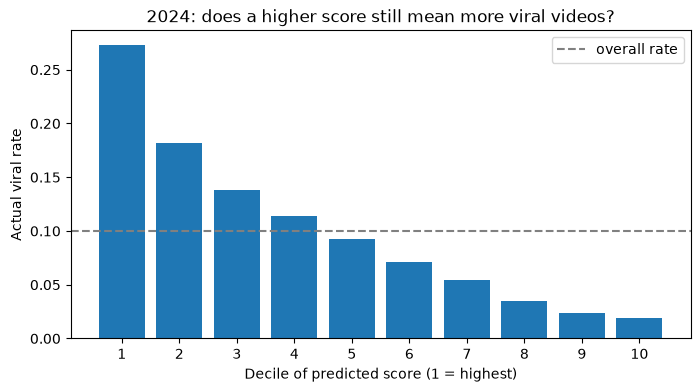

decile
1     0.273
2     0.182
3     0.138
4     0.114
5     0.092
6     0.071
7     0.055
8     0.035
9     0.024
10    0.019
Name: y, dtype: float64


In [7]:
d = pd.DataFrame({"y": y24, "p": p24})
d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = d.groupby("decile", observed=True)["y"].mean()

plt.figure(figsize=(8, 4))
plt.bar(lift.index.astype(str), lift.values)
plt.axhline(y24.mean(), ls="--", color="gray", label="overall rate")
plt.xlabel("Decile of predicted score (1 = highest)")
plt.ylabel("Actual viral rate")
plt.title("2024: does a higher score still mean more viral videos?")
plt.legend(); plt.show()
print(lift.round(3))

### Interpretation: lift chart on 2024

The actual viral rate decreases at every step from decile 1 to decile 10:
27.3%, 18.2%, 13.8%, 11.4%, 9.2%, 7.1%, 5.5%, 3.5%, 2.4%, 1.9%.
The top decile is 2.7 times the average (10%) and the bottom decile is 14 times lower than the top one.
This is the same shape as on validation (top decile about 24%, bottom about 2%), a bit stronger at the top.
The ranking is therefore reliable: the model finds likely viral videos and, just as usefully,
identifies videos that almost never go viral.


Compare with the validation lift chart (top decile about 24%, bottom decile about 2%).
Do the bars still decrease from left to right?

## 8. Month by month in 2024

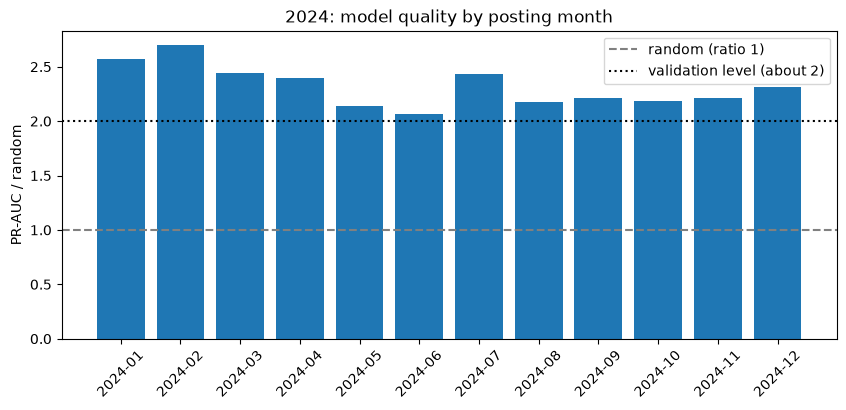

2024-01    2.57
2024-02    2.70
2024-03    2.45
2024-04    2.39
2024-05    2.14
2024-06    2.07
2024-07    2.44
2024-08    2.18
2024-09    2.21
2024-10    2.19
2024-11    2.21
2024-12    2.32
dtype: float64


In [8]:
d24["p"] = p24
months, vals = [], []
for m, g in d24.groupby(d24["cohort"].dt.strftime("%Y-%m")):
    months.append(m)
    vals.append(average_precision_score(g["is_viral"], g["p"]) / g["is_viral"].mean())

plt.figure(figsize=(10, 4))
plt.bar(months, vals)
plt.axhline(1, ls="--", color="gray", label="random (ratio 1)")
plt.axhline(2, ls=":", color="black", label="validation level (about 2)")
plt.xticks(rotation=45); plt.ylabel("PR-AUC / random")
plt.title("2024: model quality by posting month"); plt.legend(); plt.show()
print(pd.Series(vals, index=months).round(2))

### Interpretation: stability across 2024

The ratio is above 2.0 in all 12 months, from 2.07 (June) to 2.70 (February), so the model beats chance
in every month. The first four months are higher (2.39 to 2.70) and the rest sit between 2.07 and 2.44, with no steady trend.
Each month has only about 5,000 videos (about 500 viral), so differences of a few tenths between months
are mostly noise and should not be interpreted.

Importantly, the months farthest from the training period (January and February 2024) score highest.
If virality had drifted, the score would fall as we move away from 2025. We see the opposite, which supports
the idea that the learned relationships are stable.


Is the ratio stable across months, or does it fall in some of them? Each month has only about 5,000 videos (about 500 viral),
so small differences between months are noise.

## 9. Conclusion of the out-of-time check

The model trained on 2025 videos reaches a PR-AUC of 0.229 on the 2024 sample (random 0.100), a ratio of 2.28
versus random with a 95% interval of [2.20, 2.37]. This is at least as good as on validation (2.04) and test (2.12).
The signal transfers to a different year: the ratio stays above 2.0 in all 12 months of 2024, and the top decile
contains 27.3% viral videos against 1.9% in the bottom decile. The sound feature has no effect on this transfer
(ratio 2.28 with and without it).

**Interpretation.** What predicts relative success in this dataset (caption length, duration, hashtags, language,
posting hour) looks stable between 2024 and 2026. The slightly higher score in 2024 is not evidence that the model
is better there. Possible reasons are a data mix closer to train and more settled view counts, but these were not tested.

**Limits.**
- This is a backward test (train on 2025, score 2024), so it shows stable relationships, not forecasting ability.
- The 2024 sample came from 3 row groups per month and may cover limited days per month.
- The composition of the data changes across periods (US share from 94% in 2024 to 49% in test, share of photos),
  and I did not check whether this reflects the platform or the sampling.
- The label is relative (top 10% of each month), so this check says nothing about absolute view counts.
- There is still no creator information, so the signal stays modest (about twice chance).